In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from IPython.display import display
import ipywidgets as widgets

ROOT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils" / "kmeans_smote_utils.py").exists()),
    None
)
if ROOT_DIR is None:
    raise FileNotFoundError("Não encontrei a pasta 'utils'. Verifique onde kmeans_smote_utils.py está salvo.")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

candidates = [
    ROOT_DIR / "data" / "processed",
    Path.cwd() / "data" / "processed",
    Path.cwd().parent / "data" / "processed",
    Path.cwd().parent.parent / "data" / "processed",
]

DATA_DIR = next((p for p in candidates if (p / "X_train.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Não encontrei data/processed/X_train.csv. Ajuste DATA_DIR manualmente.")

from utils.kmeans_smote_utils import (
    load_processed_data,
    fit_kmeans_scenarios,
    fit_smote_mrs_scenarios,
    compare_scenarios,
    plot_metric_comparison,
    plot_resampling_counts,
    plot_contingency_heatmap,
    plot_pca_comparison,
    plot_voronoi_comparison,
    plot_feature_boxplots,
)

sns.set_theme(style="whitegrid", context="notebook")
X_train, X_test, y_train, y_test = load_processed_data(DATA_DIR)
print(f"Dados: X_train={X_train.shape}, X_test={X_test.shape}")

Dados: X_train=(10648, 24), X_test=(4564, 24)


In [2]:
N_CLUSTERS = 5
TARGET_RATIO = 0.20
RANDOM_STATE = 2005

baseline = fit_kmeans_scenarios(
    X_train, X_test,
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
)

smote_mrs = fit_smote_mrs_scenarios(
    X_train, X_test, y_train,
    n_clusters=N_CLUSTERS,
    target_ratio=TARGET_RATIO,
    random_state=RANDOM_STATE,
)


== standard ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS),Total final
0,0,10,0,0,10
1,1,2484,1847,0,4331
2,2,4737,2074,0,6811
3,3,1996,832,0,2828
4,4,1421,52,0,1473



== minmax ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS),Total final
0,0,1907,575,0,2482
1,1,1242,315,0,1557
2,2,3699,1741,0,5440
3,3,2167,554,0,2721
4,4,1633,632,0,2265



== robust ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS),Total final
0,0,324,20,0,344
1,1,1,0,0,1
2,2,1,0,0,1
3,3,10313,3173,0,13486
4,4,9,0,0,9



== quantile ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS),Total final
0,0,2305,564,0,2869
1,1,1972,1434,0,3406
2,2,2883,1736,0,4619
3,3,2051,813,0,2864
4,4,1437,189,0,1626


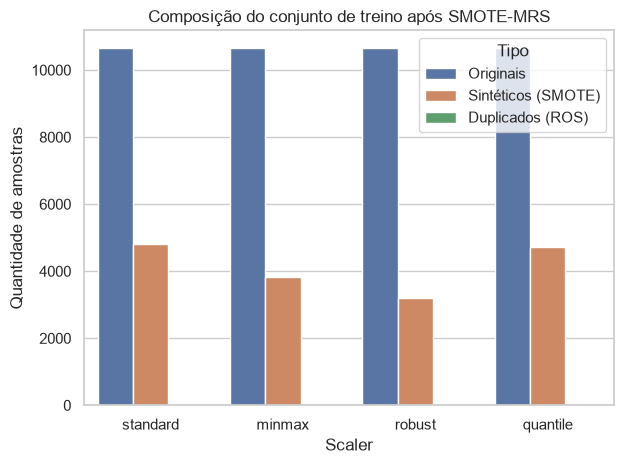

In [3]:
for scaler_name, item in smote_mrs.items():
    print(f"\n== {scaler_name} ==")
    display(item["summary"])

plot_resampling_counts(smote_mrs)
plt.tight_layout()
plt.show()


In [4]:
metrics = compare_scenarios(baseline, smote_mrs, y_test)
metrics = metrics.sort_values(["Scaler", "Cenário"]).reset_index(drop=True)
display(metrics.style.format({c: "{:.4f}" for c in metrics.columns if c not in ["Cenário", "Scaler"]}))

,Cenário,Scaler,ARI,NMI,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,SMOTE-MRS,minmax,0.0436,0.0325,0.2747,1.6837,2240.6776
1,Sem SMOTE,minmax,0.1109,0.0894,0.2533,1.5081,2453.5565
2,SMOTE-MRS,quantile,0.1548,0.1297,0.1146,2.6402,1605.6072
3,Sem SMOTE,quantile,0.1501,0.1968,0.1151,2.4584,1697.4795
4,SMOTE-MRS,robust,0.0673,0.0420,0.5601,1.0432,992.7510
5,Sem SMOTE,robust,0.0418,0.0313,0.6500,0.8478,1048.2640
6,SMOTE-MRS,standard,0.1373,0.1491,0.1072,1.9488,339.8556
7,Sem SMOTE,standard,0.2492,0.2762,0.1096,1.9699,396.0839


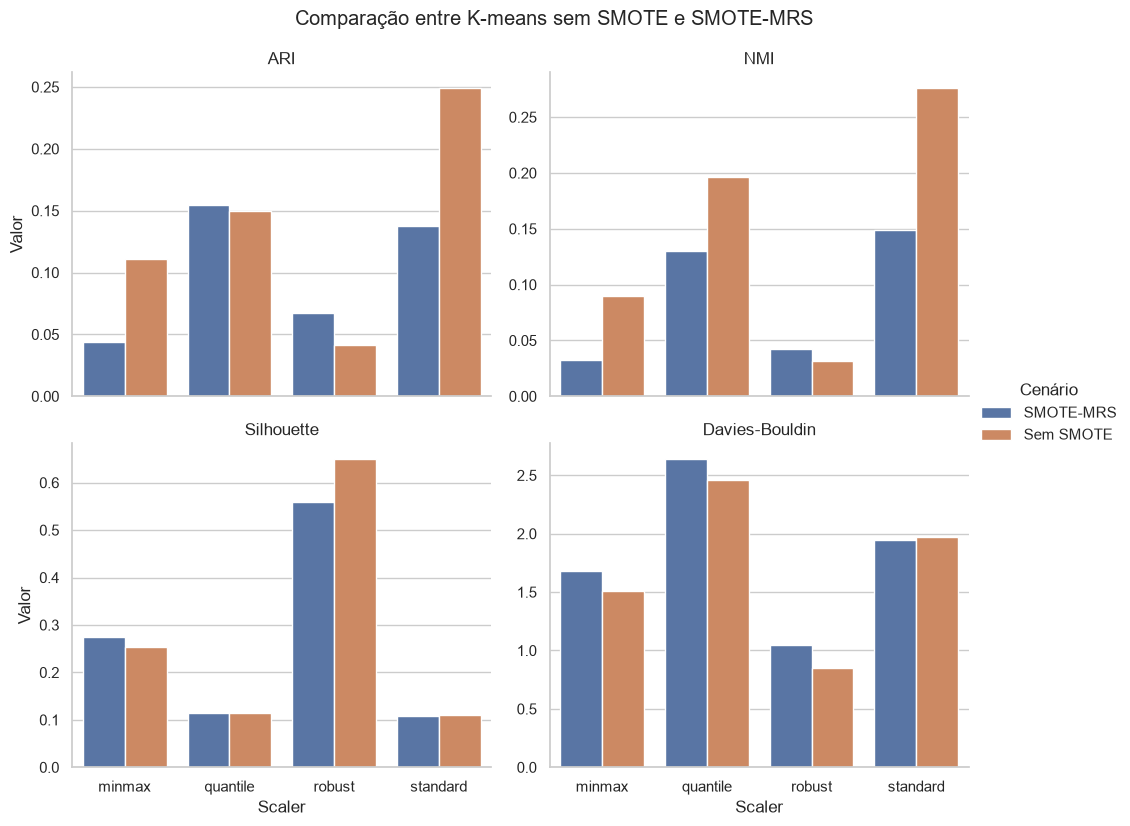

In [5]:
plot_metric_comparison(metrics)
plt.show()

In [6]:
def atualizar_pca(scaler_name):
    plot_pca_comparison(
        baseline[scaler_name],
        smote_mrs[scaler_name],
        y_test,
        title_suffix=f"— {scaler_name}",
    )
    plt.show()

widgets.interact(
    atualizar_pca,
    scaler_name=widgets.Dropdown(
        options=list(baseline.keys()),
        value="standard" if "standard" in baseline else list(baseline.keys())[0],
        description="Scaler:",
        layout=widgets.Layout(width="300px"),
    ),
);

interactive(children=(Dropdown(description='Scaler:', layout=Layout(width='300px'), options=('standard', 'minm…

In [7]:
methods = list(baseline.keys())

def atualizar_voronoi(name):
    plot_voronoi_comparison(
        baseline_item=baseline[name],
        smote_item=smote_mrs[name],
        title_suffix=f"— {name}",
    )
    plt.show()

widgets.interact(
    atualizar_voronoi,
    name=widgets.Dropdown(
        options=methods,
        value="standard" if "standard" in methods else methods[0],
        description="Scaler:",
        layout=widgets.Layout(width="300px"),
    ),
);

interactive(children=(Dropdown(description='Scaler:', layout=Layout(width='300px'), options=('standard', 'minm…

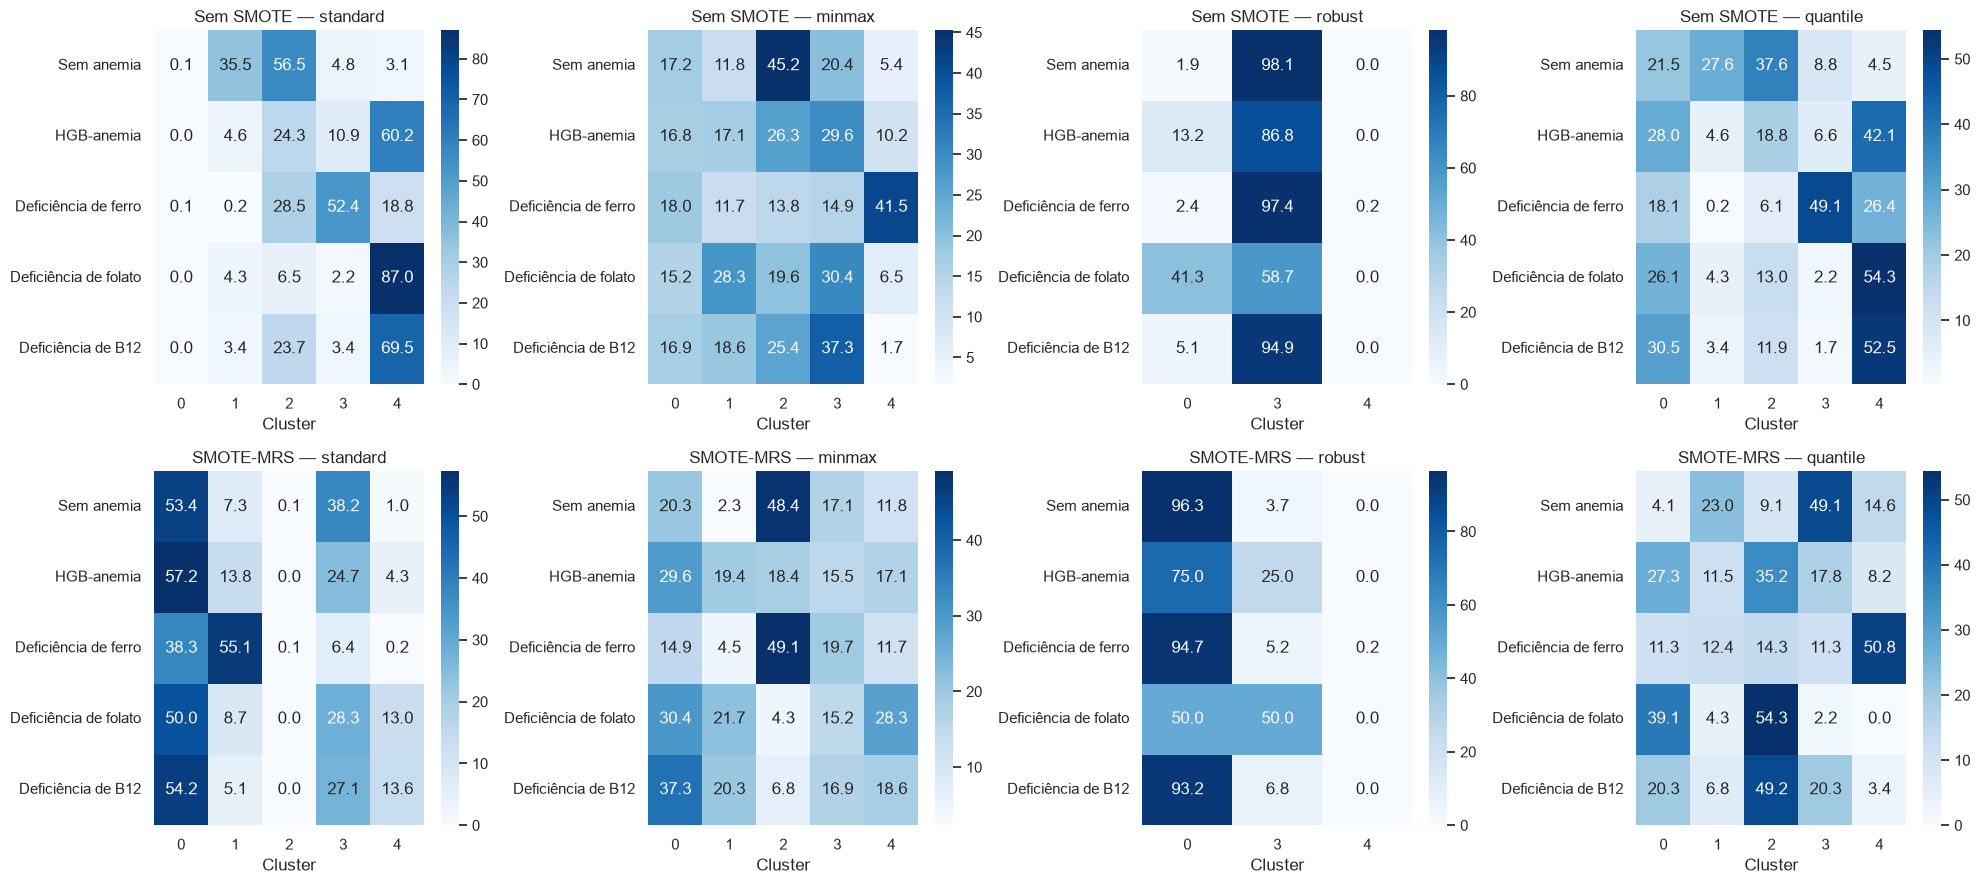

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for col, scaler_name in enumerate(baseline):
    plot_contingency_heatmap(baseline[scaler_name], y_test, normalize=True, ax=axes[0, col])
    axes[0, col].set_title(f"Sem SMOTE — {scaler_name}")
    plot_contingency_heatmap(smote_mrs[scaler_name], y_test, normalize=True, ax=axes[1, col])
    axes[1, col].set_title(f"SMOTE-MRS — {scaler_name}")
plt.tight_layout()
plt.show()

In [9]:
todas_colunas = list(X_test.columns)

valor_inicial = "HGB" if "HGB" in todas_colunas else todas_colunas[0]

def atualizar_grafico(feature):
    plot_feature_boxplots(baseline["robust"], smote_mrs["robust"], X_test, feature)
    plt.show()

widgets.interact(
    atualizar_grafico,
    feature=widgets.Dropdown(
        options=todas_colunas,
        value=valor_inicial,
        description="Coluna:",
        layout=widgets.Layout(width="350px")
    )
);

interactive(children=(Dropdown(description='Coluna:', index=8, layout=Layout(width='350px'), options=('GENDER'…